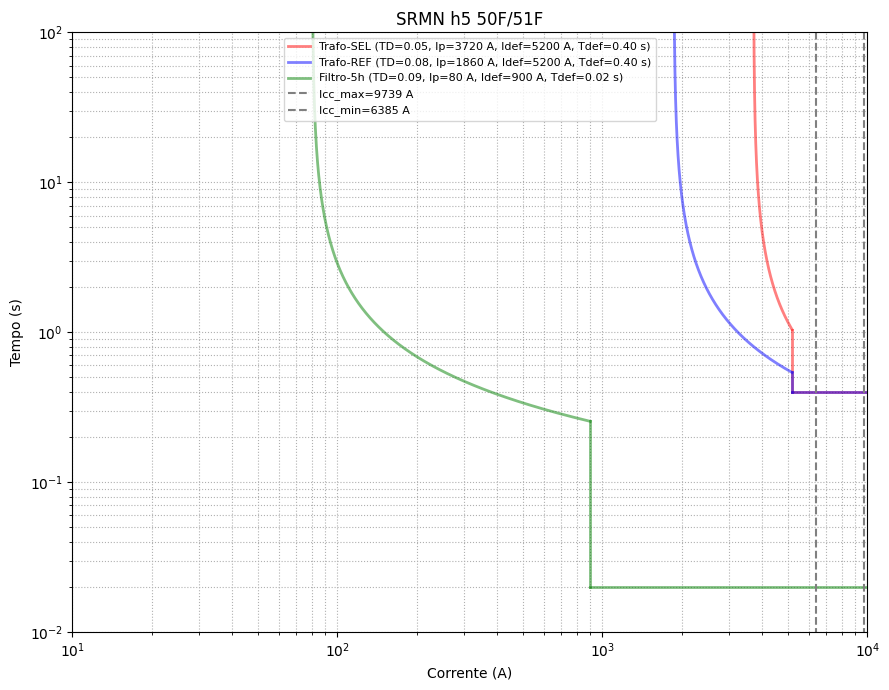

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def iec_inverse_time(I, I_pickup, A, P, time_dial):
    """
    IEC inverse-time equation.
    """
    M = I / I_pickup
    M = np.maximum(M, 1.0001)
    t = time_dial * A / (np.power(M, P) - 1.0)
    return t


def plot_iec_with_definite(curve_dicts,
                           I_min=10.0,
                           I_max=10000.0,
                           n_points=3000,
                           t_max=100.0,
                           axis_and_titles=None):

    fig = plt.figure(figsize=(9, 7))

    for curve in curve_dicts:
        label = curve["label"]
        A = curve["A"]
        P = curve["P"]
        TD = curve["TD"]
        I_pickup = curve["Ipickup"]
        I_def = curve["Idef"]
        T_def = curve["Tdef"]
        color = curve["color"]
        linestyle = curve["linestyle"]
        linewidth = curve["linewidth"]
        alpha = curve.get("alpha", 1.0)   # transparency

        # Legend string with key parameters
        legend_label = (
            f"{label} "
            f"(TD={TD:.2f}, Ip={I_pickup:.0f} A, "
            f"Idef={I_def:.0f} A, Tdef={T_def:.2f} s)"
        )

        # Inverse curve segment
        I_start = max(I_min, 1.0001 * I_pickup)
        I_end_inv = min(I_def, I_max)

        I_values_inv = np.linspace(I_start, I_end_inv, n_points)
        t_values_inv = iec_inverse_time(I_values_inv, I_pickup, A, P, TD)

        if I_values_inv.size > 0:
            plt.loglog(
                I_values_inv,
                t_values_inv,
                color=color,
                label=legend_label,   # legend with parameters
                linestyle=linestyle,
                linewidth=linewidth,
                alpha=alpha
            )

        # Time at Idef
        t_at_Idef = iec_inverse_time(np.array([I_def]), I_pickup, A, P, TD)[0]

        # Only draw definite segments if under t_max
        if t_at_Idef <= t_max and T_def <= t_max:

            # Vertical segment (no legend)
            plt.loglog(
                [I_def, I_def],
                [t_at_Idef, T_def],
                color=color,
                linestyle=linestyle,
                linewidth=linewidth,
                alpha=alpha
            )

            # Horizontal definite segment (no legend)
            plt.loglog(
                [I_def, I_max],
                [T_def, T_def],
                color=color,
                linestyle=linestyle,
                linewidth=linewidth,
                alpha=alpha
            )

    # Apply optional title/labels
    if axis_and_titles is not None:
        plt.xlabel(axis_and_titles.get("xlabel", ""))
        plt.ylabel(axis_and_titles.get("ylabel", ""))
        plt.title(axis_and_titles.get("title", ""))

    plt.grid(True, which="both", ls=":")
    plt.xlim(I_min, I_max)
    plt.ylim(0.01, 100)
    plt.tight_layout()
    return fig



if __name__ == "__main__":
    A_SI = 0.14
    P_SI = 0.02

    curves = [
        {
            "label":"Trafo-SEL",
            "A":A_SI,
            "P":P_SI,
            "TD":0.05,
            "Ipickup":3720.0,
            "Idef":5200.0,
            "Tdef":0.4,
            "color":"red",
            "linestyle":"-",
            "linewidth":2,
            "alpha":0.5
        },
        {
            "label":"Trafo-REF",
            "A":A_SI,
            "P":P_SI,
            "TD":0.08,
            "Ipickup":1860.0,
            "Idef":5200.0,
            "Tdef":0.4,
            "color":"blue",
            "linestyle":"-",
            "linewidth":2,
            "alpha":0.5
        },
        {
            "label":"Filtro-5h",
            "A":A_SI,
            "P":P_SI,
            "TD":0.09,
            "Ipickup":80.33,
            "Idef":900.0,
            "Tdef":0.02,
            "color":"green",
            "linestyle":"-",
            "linewidth":2,
            "alpha":0.5
        }
    ]

    Icc_max=9739
    Icc_min=6385

    axis_and_titles = {
        "xlabel": "Corrente (A)",
        "ylabel": "Tempo (s)",
        "title": "SRMN h5 50F/51F"
    }

    fig = plot_iec_with_definite(curves, axis_and_titles=axis_and_titles)
    plt.loglog([Icc_max, Icc_max], [0, 1000], color="gray", ls="--", label=f"Icc_max={Icc_max} A")
    plt.loglog([Icc_min, Icc_min], [0, 1000], color="gray", ls="--", label=f"Icc_min={Icc_min} A")
    plt.legend(loc="upper center", fontsize=8)
    fig.show()
